In [1]:
import pickle
import torch
import random
import numpy as np
from torch import nn

from datasets import load_dataset, load_from_disk, Dataset
from torch.utils.data import DataLoader,TensorDataset

from torchinfo import summary
from sklearn.metrics import roc_auc_score, confusion_matrix

from mhcicleave.models import MLP, CNN

In [2]:

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


In [3]:
# Utility Functions
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

def process_batch(batch, enc_type="concat"):
    encoding = batch["encoded_sequences"]
    labels = batch["elution_cleavage"]
    
    if enc_type == "concat":
        encoding = encoding.flatten(0)  # Global representation (concatenate)
    elif enc_type == "avg":
        encoding = encoding.mean(2)  # Global representation (average)
    
    return {"encoded_sequences": encoding, "sequence_labels": labels}

set_seed(99)

In [4]:
# Data Loading and Preprocessing
def load_blosum_dataset(datasetpath, enc_type="concat"):
    blosum_dataset = load_from_disk(datasetpath)
    blosum_dataset.set_format(type="torch")
    blosum_dataset_concat = blosum_dataset.map(process_batch, 
                                               fn_kwargs={"enc_type": enc_type}, 
                                               remove_columns=["elution_cleavage"])
    blosum_dataset_concat = blosum_dataset_concat.class_encode_column("sequence_labels")
    return blosum_dataset_concat

def load_esm2_embeddings(filepath):
    with open(filepath, "rb") as f:
        esm2_concat_dict = pickle.load(f)
    return esm2_concat_dict

In [5]:
# Model Initialization
def init_mlp(model_params):
    return MLP(**model_params).to(DEVICE)

def init_cnn(model_params):
    return CNN(**model_params).to(DEVICE)


In [6]:
# 
def get_nn_repr(model, dataset, layer_name="fc2"):
    # Create a dictionary to store the layer outputs
    layer_outputs = []

    # Hook function to capture the output of the specified layer
    def hook_function(module, input, output):
        layer_outputs.append(output.cpu().detach().numpy())

    # Register the hook
    layer = dict(model.named_modules())[layer_name]
    hook = layer.register_forward_hook(hook_function)

    # Run the model on the dataset
    model.eval()
    with torch.no_grad():
        for data in DataLoader(dataset, batch_size=512):  # Example batch size
            inputs = data["encoded_sequences"].to(DEVICE)
            model(inputs)

    # Remove the hook
    hook.remove()

    # clean up gpu
    del model
    del dataset
    torch.cuda.empty_cache()

    return np.concatenate(layer_outputs, axis=0)

In [7]:
# no padding and no tokenization, we are giving output embedding directly to CNN layers

# Get last layer representation with and without training

### Loading Data, init models and params

In [9]:
# Load datasets
blosum_concat_dataset = load_blosum_dataset("../data/encodings/blosum62/")
esm2_concat_dict = load_esm2_embeddings("../data/encodings/esm2_concat_test50540.pkl")

esm2_concat_dataset = Dataset.from_dict(esm2_concat_dict)
esm2_concat_dataset.set_format("torch")
esm2_concat_dataset = esm2_concat_dataset.rename_columns({'label': 'sequence_labels', 'embeddings': 'encoded_sequences'})

In [15]:
# Init models

blosum_features = 23
seq_len = 10
esm2_dim = 1280

MLP_PARAMS_blosum_concat = {"input_size":seq_len*blosum_features,"hidden_linear1":256,"hidden_linear2":128,"out_neurons":1,"dropout":0.5}
MLP_PARAMS_esm2_concat = {"input_size":seq_len*esm2_dim,"hidden_linear1":256,"hidden_linear2":128,"out_neurons":1,"dropout":0.5}
CNN_PARAMS_esm2_concat = {"input_channel":1,"out_channel1":32,"out_channel2":64,"kernel_size1":1280,"stride1":1280,"kernel_size2":3,"stride2":1}
CNN_PARAMS_blosum_concat = {"input_channel":1,"out_channel1":32,"out_channel2":64,"kernel_size1":23,"stride1":23,"kernel_size2":3,"stride2":1}



# Initialize models with different input dimensions
mlp_model_blosum = init_mlp(MLP_PARAMS_blosum_concat)  # Input size for blosum
mlp_model_esm2 = init_mlp(MLP_PARAMS_esm2_concat)  # Input size for esm2
cnn_model_esm2 = init_cnn(CNN_PARAMS_esm2_concat)  # 
cnn_model_blosum = init_cnn(CNN_PARAMS_blosum_concat)  # 


In [9]:
summary(cnn_model_blosum,input_size=(1,230))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      --                        --
├─Conv1d: 1-1                            [1, 32, 10]               768
├─Conv1d: 1-2                            [1, 64, 10]               6,208
├─Linear: 1-3                            [1, 1]                    65
Total params: 7,041
Trainable params: 7,041
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.07
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.03
Estimated Total Size (MB): 0.04

In [10]:
summary(cnn_model_esm2,input_size=(1,12800))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      --                        --
├─Conv1d: 1-1                            [1, 32, 10]               40,992
├─Conv1d: 1-2                            [1, 64, 10]               6,208
├─Linear: 1-3                            [1, 1]                    65
Total params: 47,265
Trainable params: 47,265
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.47
Input size (MB): 0.05
Forward/backward pass size (MB): 0.01
Params size (MB): 0.19
Estimated Total Size (MB): 0.25

In [14]:
#summary(model, input_data=blosum_dataset_["train"]["encoded_sequences"].to(DEVICE))
summary(mlp_model_esm2,(1,12800))

Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      --                        --
├─Linear: 1-1                            [1, 256]                  3,277,056
├─Dropout: 1-2                           [1, 256]                  --
├─Linear: 1-3                            [1, 128]                  32,896
├─Dropout: 1-4                           [1, 128]                  --
├─Linear: 1-5                            [1, 1]                    129
Total params: 3,310,081
Trainable params: 3,310,081
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 3.31
Input size (MB): 0.05
Forward/backward pass size (MB): 0.00
Params size (MB): 13.24
Estimated Total Size (MB): 13.29

### Extract and save last layers representations of model without training

In [11]:
# Extract and save last layers representations
# blosum_features = get_nn_repr(mlp_model_blosum, blosum_concat_dataset, layer_name="fc2")
# esm2_features = get_nn_repr(mlp_model_esm2, esm2_concat_dataset, layer_name="fc2")

blosum_features2 = get_nn_repr(cnn_model_blosum, blosum_concat_dataset, layer_name="cov2")
esm2_features2 = get_nn_repr(cnn_model_esm2, esm2_concat_dataset, layer_name="cov2")


In [13]:
## save embeddings

In [17]:
blosum_concat_mlp_dict = {"labels":blosum_concat_dataset["sequence_labels"],
                         "encoding":blosum_features}

esm2_concat_mlp_dict = {"labels":esm2_concat_dataset["sequence_labels"],
                         "encoding":esm2_features}

blosum_concat_cnn_dict = {"labels":blosum_concat_dataset["sequence_labels"],
                         "encoding":blosum_features2}

esm2_concat_cnn_dict = {"labels":esm2_concat_dataset["sequence_labels"],
                         "encoding":esm2_features2}

In [18]:
with open("../data/encodings/blosum_concat_test50540_MLPnotrain.pkl", "wb") as f:
    pickle.dump(blosum_concat_mlp_dict, f)

with open("../data/encodings/esm2_concat_test50540_MLPnotrain.pkl", "wb") as f:
    pickle.dump(esm2_concat_mlp_dict, f)

with open("../data/encodings/blosum_concat_test50540_CNNnotrain.pkl", "wb") as f:
    pickle.dump(blosum_concat_cnn_dict, f)

with open("../data/encodings/esm2_concat_test50540_CNNnotrain.pkl", "wb") as f:
    pickle.dump(esm2_concat_cnn_dict, f)

## Train models and get last layer representation

In [7]:
from sklearn.metrics import accuracy_score, roc_auc_score
import matplotlib.pyplot as plt
from tempfile import TemporaryDirectory
import time
import os
from tqdm import tqdm
import torch.optim as optim
from torch.optim import lr_scheduler

def train_model(model, criterion, optimizer, scheduler, dataloaders, DEVICE, num_epochs=25):
    since = time.time()
    history = []

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0
        
        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            epoch_data = {'epoch': epoch}
            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                preds, lbls = [], []

                # Iterate over data
                for batch in tqdm(dataloaders[phase]):
                    inputs = batch["encoded_sequences"].to(DEVICE)
                    labels = batch["sequence_labels"].to(DEVICE).float()

                    # Zero the parameter gradients
                    optimizer.zero_grad()

                    # Forward pass
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs).squeeze()
                        loss = criterion(outputs, labels)

                        # Backward pass + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # Accumulate loss and predictions
                    running_loss += loss.item() * inputs.size(0)
                    preds.extend(torch.sigmoid(outputs).detach().cpu().numpy())
                    lbls.extend(labels.detach().cpu().numpy())

                # Compute metrics
                epoch_loss = running_loss / len(dataloaders[phase].dataset)
                if phase == 'train':
                    scheduler.step()
                    epoch_data['loss'] = epoch_loss
                else:
                    epoch_data['eval_loss'] = epoch_loss
                    if len(set(lbls)) > 1:  # Ensure valid ROC calculation
                        epoch_data['eval_auc'] = roc_auc_score(lbls, preds)

                print(f'{phase} Loss: {epoch_loss:.4f}')
                if 'eval_auc' in epoch_data:
                    print(f'{phase} AUC: {epoch_data["eval_auc"]:.4f}')
            
            history.append(epoch_data)

            # Save the best model weights
            if 'eval_auc' in epoch_data and epoch_data['eval_auc'] > best_acc:
                best_acc = epoch_data['eval_auc']
                torch.save(model.state_dict(), best_model_params_path)

        # Training summary
        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val AUC: {best_acc:.4f}')

        # Load best model weights
        model.load_state_dict(torch.load(best_model_params_path))


    return model, history



def plot_training_history(history):
    # Extract metrics from history
    loss = [x['loss'] for x in history if 'loss' in x]
    val_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
    metric = [x['eval_auc'] for x in history if 'eval_auc' in x]
    epochs = [x['epoch'] for x in history]

    # Create a figure with two y-axes
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax2 = ax1.twinx()

    # Plot loss and val_loss on the first y-axis
    line1 = ax1.plot(epochs, loss, label='train_loss', color='blue')
    line2 = ax1.plot(epochs, val_loss, label='val_loss', color='orange')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')

    # Plot the computed metric on the second y-axis
    line3 = ax2.plot(epochs, metric, label='val_auc', color='red')
    ax2.set_ylabel('AUC')
    ax2.set_ylim([0, 1])

    # Combine the lines from both y-axes and create a single legend
    lines = line1 + line2 + line3
    labels = [line.get_label() for line in lines]
    ax1.legend(lines, labels, loc='lower left')

    # Show the plot
    plt.title("Training History")
    #plt.show()


In [10]:
# split data into train test
blosum_dataset_split = blosum_concat_dataset.train_test_split(test_size=0.1,seed=0,stratify_by_column="sequence_labels")
blosum_trainloader = DataLoader(blosum_dataset_split["train"], batch_size=512)
blosum_testloader = DataLoader(blosum_dataset_split["test"], batch_size=512)

In [11]:
blosum_loaders = {"train":blosum_trainloader, "val":blosum_testloader}

In [12]:
from torch import nn
import torch.nn.functional as F


class CNN(nn.Module):
    def __init__(self, input_channel, out_channel1,out_channel2, kernel_size1, kernel_size2,
                 stride1,stride2) -> None:
        super().__init__()

        self.cov1 = nn.Conv1d(input_channel, out_channel1, kernel_size=kernel_size1, stride=stride1,
                              padding=0)
        self.batchnorm1 = nn.BatchNorm1d(out_channel1)
        self.cov2 = nn.Conv1d(out_channel1, out_channel2, kernel_size=kernel_size2, stride=stride2,
                              padding=1)
        self.batchnorm2 = nn.BatchNorm1d(out_channel2)
        self.dense = nn.Linear(out_channel2,1)

    def forward(self, x):
        #x = x.permute(0, 2, 1).contiguous()
        x = x.unsqueeze(1)
        x = self.cov1(x)
        x = self.batchnorm1(x)
        x = F.relu(x)
        x = self.cov2(x)
        x = self.batchnorm2(x)
        x = F.relu(x)

        # Global average pooling over the sequence dimension
        x = x.mean(dim=-1)  # Now x is [batch_size, out_channel2]
        out = F.sigmoid(self.dense(x))  # [batch, 1]

        return out.squeeze()

In [13]:
experiment_log = []


In [14]:
# Clear GPU memory
torch.cuda.empty_cache()
cnn_model_blosum = None
if cnn_model_blosum:
    del cnn_model_blosum
# Reinitialize model
CNN_PARAMS_blosum_concat = {"input_channel":1,"out_channel1":64,"out_channel2":32,"kernel_size1":23,"stride1":23,"kernel_size2":3,"stride2":1}
cnn_model_blosum = init_cnn(CNN_PARAMS_blosum_concat)


In [15]:
summary(cnn_model_blosum,input_size=(1,230))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      --                        --
├─Conv1d: 1-1                            [1, 64, 10]               1,536
├─BatchNorm1d: 1-2                       [1, 64, 10]               128
├─Conv1d: 1-3                            [1, 32, 10]               6,176
├─BatchNorm1d: 1-4                       [1, 32, 10]               64
├─Linear: 1-5                            [1, 1]                    33
Total params: 7,937
Trainable params: 7,937
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.08
Input size (MB): 0.00
Forward/backward pass size (MB): 0.02
Params size (MB): 0.03
Estimated Total Size (MB): 0.05

In [16]:

# Reinitialize optimizer and scheduler
optimizer = optim.Adam(cnn_model_blosum.parameters(), lr=0.001,weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss()
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

# Train the model
cnn_model_blosum_trained = train_model(
    cnn_model_blosum, criterion, optimizer, scheduler, blosum_loaders, DEVICE, num_epochs=15
)

experiment_log = []
# Log experiment
experiment_log.append({
    'model': 'CNN_Blosum',
    'model_params':CNN_PARAMS_blosum_concat,
    'input_dim': 230,
    'optimizer': 'Adam',
    'lr': 0.001,
    'weight_decay': 1e-5,
    'scheduler': 'StepLR',
    'metrics': {'val_loss': cnn_model_blosum_trained[1][-1]['eval_loss'], 'val_auc': cnn_model_blosum_trained[1][-1]['eval_auc']}
})

Epoch 0/14
----------


100%|███████████████████████████████████████████████████████████████████████████████████| 89/89 [00:03<00:00, 27.97it/s]


train Loss: 0.6691


100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 69.68it/s]


val Loss: 0.6514
val AUC: 0.7796
Epoch 1/14
----------


100%|███████████████████████████████████████████████████████████████████████████████████| 89/89 [00:01<00:00, 68.01it/s]


... (51 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████| 89/89 [00:01<00:00, 69.71it/s]


train Loss: 0.6140


100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 94.05it/s]

val Loss: 0.6220
val AUC: 0.8183
Training complete in 0m 24s
Best val AUC: 0.8183


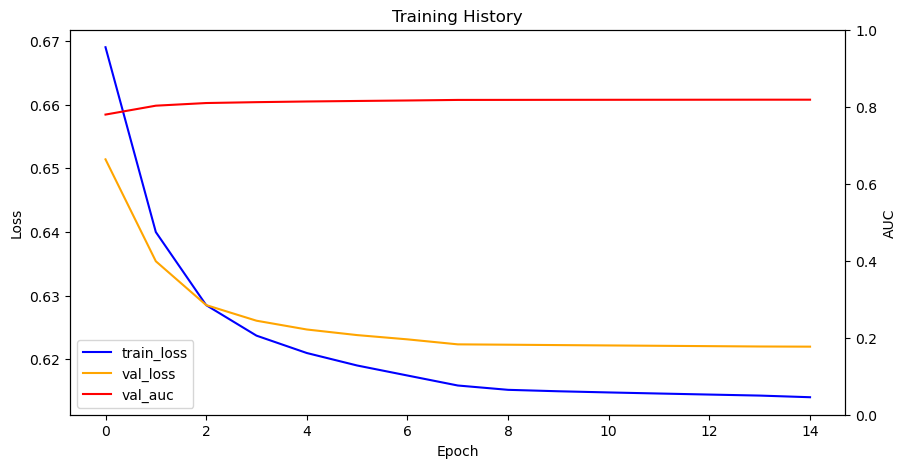

In [18]:
plot_training_history(cnn_model_blosum_trained[1])
plt.savefig(f'../outputs/cnn_model_blosum_trained.png',format='png',bbox_inches='tight',dpi=300)

### Get representations from trained model and save it

In [19]:
# Extract and save representations
blosum_features_CNNtrained = get_nn_repr(cnn_model_blosum_trained[0], blosum_concat_dataset, layer_name="cov2")


In [20]:
blosum_concat_CNNTrained_dict = {"labels":blosum_concat_dataset["sequence_labels"],
                         "encoding":blosum_features_CNNtrained}

with open("../data/encodings/blosum_concat_test50540_CNNtrained.pkl", "wb") as f:
    pickle.dump(blosum_concat_CNNTrained_dict, f)


## Train CNN  with ESM-2 embedding

In [21]:
esm2_concat_dataset = esm2_concat_dataset.class_encode_column("sequence_labels")

# split data into train test
esm2_dataset_split = esm2_concat_dataset.train_test_split(test_size=0.1,seed=0,stratify_by_column="sequence_labels")
esm2_trainloader = DataLoader(esm2_dataset_split["train"], batch_size=512)
esm2_testloader = DataLoader(esm2_dataset_split["test"], batch_size=512)

esm2_loaders = {"train":esm2_trainloader, "val":esm2_testloader}

Stringifying the column:   0%|          | 0/50540 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/50540 [00:00<?, ? examples/s]

In [22]:
experiment_log2 = []

In [23]:
# Clear GPU memory
torch.cuda.empty_cache()
cnn_model_esm2 = None
if cnn_model_esm2:
    del cnn_model_esm2
# Reinitialize model
CNN_PARAMS_esm2_concat = {"input_channel":1,"out_channel1":64,"out_channel2":32,"kernel_size1":1280,"stride1":1280,"kernel_size2":3,"stride2":1}

cnn_model_esm2 = init_cnn(CNN_PARAMS_esm2_concat)


In [24]:
summary(cnn_model_esm2,input_size=(1,12800))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      --                        --
├─Conv1d: 1-1                            [1, 64, 10]               81,984
├─BatchNorm1d: 1-2                       [1, 64, 10]               128
├─Conv1d: 1-3                            [1, 32, 10]               6,176
├─BatchNorm1d: 1-4                       [1, 32, 10]               64
├─Linear: 1-5                            [1, 1]                    33
Total params: 88,385
Trainable params: 88,385
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.88
Input size (MB): 0.05
Forward/backward pass size (MB): 0.02
Params size (MB): 0.35
Estimated Total Size (MB): 0.42

In [25]:
# Reinitialize optimizer and scheduler
optimizer = optim.Adam(cnn_model_esm2.parameters(), lr=0.001)
criterion = nn.BCEWithLogitsLoss()
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

# Train the model
cnn_model_esm2_trained = train_model(
    cnn_model_esm2, criterion, optimizer, scheduler, esm2_loaders, DEVICE, num_epochs=20
)

experiment_log = []
# Log experiment
experiment_log.append({
    'model': 'CNN_ESM2',
    'model_params':CNN_PARAMS_esm2_concat,
    'input_dim': 12800,
    'optimizer': 'Adam',
    'lr': 0.001,
    'weight_decay': 1e-5,
    'scheduler': 'StepLR',
    'metrics': {'val_loss': cnn_model_esm2_trained[1][-1]['eval_loss'], 'val_auc': cnn_model_esm2_trained[1][-1]['eval_auc']}
})

Epoch 0/19
----------


100%|███████████████████████████████████████████████████████████████████████████████████| 89/89 [00:02<00:00, 32.43it/s]


train Loss: 0.6747


100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 46.09it/s]


val Loss: 0.6451
val AUC: 0.7933
Epoch 1/19
----------


100%|███████████████████████████████████████████████████████████████████████████████████| 89/89 [00:02<00:00, 44.19it/s]


... (71 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████| 89/89 [00:02<00:00, 37.53it/s]


train Loss: 0.5898


100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 47.49it/s]

val Loss: 0.6120
val AUC: 0.8448
Training complete in 0m 53s
Best val AUC: 0.8448


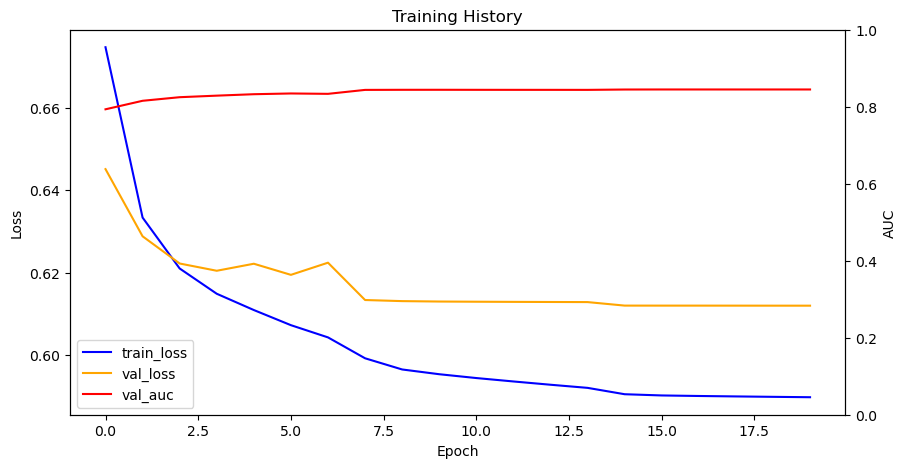

In [27]:
plot_training_history(cnn_model_esm2_trained[1])
plt.savefig(f'../outputs/cnn_model_esm2_trained.png',format='png',bbox_inches='tight',dpi=300)

In [28]:
# Extract and save representations
esm2_features_CNNtrained = get_nn_repr(cnn_model_esm2_trained[0], esm2_concat_dataset, layer_name="cov2")


In [29]:
esm2_concat_CNNTrained_dict = {"labels":esm2_concat_dataset["sequence_labels"],
                         "encoding":esm2_features_CNNtrained}

with open("../data/encodings/esm2_concat_test50540_CNNtrained.pkl", "wb") as f:
    pickle.dump(esm2_concat_CNNTrained_dict, f)
